# 实验报告02：NumPy、SciPy、Matplotlib与 pandas 数据处理

# 一、实验环境与提交要求
1. 请使用独立的 conda 虚拟环境完成实验，不得使用 base 环境。在该环境中准备
Python 3、Jupyter Notebook、NumPy、SciPy、Matplotlib 和 pandas。
2. 请先将第一个代码框中的学号修改为自己的学号，再按顺序运行各代码框。可在
PyCharm 或 VS Code 中完成。
3. 使用 Markdown 单元格解释关键结果；使用代码单元格完成计算。图表须有标题、
坐标轴标签和必要的图例。
4. 涉及随机抽样的实验请设置固定种子。
5. 提交前重启内核并运行全部代码，检查依赖和输出。只提交命名为 学号_姓名
_exp02.ipynb 的 Notebook。
## 1.1 第一个代码框：身份与环境记录

In [77]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244080301

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] exp02
[学号]       20244080301
[机器指纹] 4893301fd6adb35f
[RUN_ID]   20244080301-4893301fd6adb35f


# 二、实验内容与过程
## 实验1：NumPy 数组、数据类型与索引
操作任务：
1. 分别创建整数、浮点数和布尔值 ndarray，输出每个数组的 dtype、shape 和
ndim。解释 NumPy 数组的数据类型与 Python 列表的差别。
2. 用 np.arange(12) 创建一维数组，并分别变为形状 (3, 4) 和 (2, 3, 2) 的
数组。展示数组内容，说明改变形状时元素总数必须满足什么条件。
3. 对形状为 (3, 4) 的数组完成以下索引：取第 2 行、取第 1 至第 3 列、取大于 6
的元素，并分别输出结果及其形状。
4. 使用 np.arange(10) 分别选出“小于 2 或大于 7”和“大于 3 且小于 7”的元素。使
用括号配合 |、& 或 np.logical_or()、np.logical_and()。
5. 使用 np.arange(10) 分别选出“小于 2 或大于 7”和“大于 3 且小于 7”的元素。使
用括号配合 |、& 或 np.logical_or()、np.logical_and()。

In [78]:
# 分别创建整数、浮点数和布尔值 ndarray，输出每个数组的 dtype、shape 和ndim。解释 NumPy 数组的数据类型与 Python 列表的差别。
arr_int = np.array([1,2,3,4,5],dtype=np.int64)
arr_float = np.array([[1.5,2.5],[3.5,4.5]],dtype=np.float64)
arr_bool = np.array([True,False,True],dtype=np.bool_)

for name, arr in [("整数数组", arr_int), ("浮点数组", arr_float), ("布尔数组", arr_bool)]:
    print(f"【{name}】 内容: {arr.tolist()} | dtype: {arr.dtype} | shape: {arr.shape} | ndim: {arr.ndim}")


【整数数组】 内容: [1, 2, 3, 4, 5] | dtype: int64 | shape: (5,) | ndim: 1
【浮点数组】 内容: [[1.5, 2.5], [3.5, 4.5]] | dtype: float64 | shape: (2, 2) | ndim: 2
【布尔数组】 内容: [True, False, True] | dtype: bool | shape: (3,) | ndim: 1


In [79]:
# 用 np.arange(12) 创建一维数组，并分别变为形状 (3, 4) 和 (2, 3, 2) 的数组。展示数组内容，说明改变形状时元素总数必须满足什么条件。
arr_1d = np.arange(12)
print("原始数组:", arr_1d)

arr_3x4 = arr_1d.reshape(3, 4)
print("\n形状 (3, 4) 的数组:\n", arr_3x4)

arr_2x3x2 = arr_1d.reshape(2, 3, 2)
print("\n形状 (2, 3, 2) 的数组:\n", arr_2x3x2)

原始数组: [ 0  1  2  3  4  5  6  7  8  9 10 11]

形状 (3, 4) 的数组:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

形状 (2, 3, 2) 的数组:
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


In [80]:
# 对形状为 (3, 4) 的数组完成以下索引：取第 2 行、取第 1 至第 3 列、取大于 6的元素，并分别输出结果及其形状。
row_2 = arr_3x4[1, :]
print("第 2 行:", row_2, "| shape:", row_2.shape)

cols_1_to_3 = arr_3x4[:, 0:3]
print("\n第 1 至第 3 列:\n", cols_1_to_3, "\n| shape:", cols_1_to_3.shape)

gt_6 = arr_3x4[arr_3x4 > 6]
print("\n大于 6 的元素:", gt_6, "| shape:", gt_6.shape)

第 2 行: [4 5 6 7] | shape: (4,)

第 1 至第 3 列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] 
| shape: (3, 3)

大于 6 的元素: [ 7  8  9 10 11] | shape: (5,)


In [81]:
# 使用 np.arange(10) 分别选出“小于 2 或大于 7”和“大于 3 且小于 7”的元素。使用括号配合 |、& 或 np.logical_or()、np.logical_and()。
x = np.arange(10) # [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

cond1_op = x[(x < 2) | (x > 7)]
cond1_fn = x[np.logical_or(x < 2, x > 7)]

cond2_op = x[(x > 3) & (x < 7)]
cond2_fn = x[np.logical_and(x > 3, x < 7)]

print("小于 2 或大于 7 (运算符 |):", cond1_op)
print("小于 2 或大于 7 (函数法)  :", cond1_fn)
print("大于 3 且小于 7 (运算符 &):", cond2_op)
print("大于 3 且小于 7 (函数法)  :", cond2_fn)

小于 2 或大于 7 (运算符 |): [0 1 8 9]
小于 2 或大于 7 (函数法)  : [0 1 8 9]
大于 3 且小于 7 (运算符 &): [4 5 6]
大于 3 且小于 7 (函数法)  : [4 5 6]


In [82]:
# 使用 np.arange(10) 分别选出“小于 2 或大于 7”和“大于 3 且小于 7”的元素。使用括号配合 |、& 或 np.logical_or()、np.logical_and()。
A = np.array([[1, 2], 
              [3, 4]])
B = np.array([[5, 6], 
              [7, 8]])

elem_mul_1 = A * B
elem_mul_2 = np.multiply(A, B)

mat_mul_1 = A @ B
mat_mul_2 = np.matmul(A, B)

print("逐元素乘法 (A * B / np.multiply):\n", elem_mul_1)
print("\n矩阵乘法 (A @ B / np.matmul):\n", mat_mul_1)

逐元素乘法 (A * B / np.multiply):
 [[ 5 12]
 [21 32]]

矩阵乘法 (A @ B / np.matmul):
 [[19 22]
 [43 50]]


## 实验2：随机抽样、统计与缺失值
操作任务：
1. 使用 np.random 生成 1,000 个均值为 70、标准差为 10 的模拟成绩；用np.clip
将数值限制在 0〜100 范围内。输出样本数、最小值、最大值、均值、标准差和极
差。
2. 从 np.arange(1, 11) 中不放回地抽取 5 个整数，比较均匀抽样与按整数大小成
比例加权抽样的写法。
3. 分别演示随机排列后保留原数组和原地打乱数组，打印操作前后的原数组以说明两
种方式的区别。
4. 将模拟成绩的第 10、20、30 个值设为 np.nan。比较普通均值和忽略缺失值后的
均值，统计缺失值个数，并说明 nan 对普通统计函数的影响。
5. 将含缺失值的模拟成绩及其序号整理成内存中的表格变量，供实验4直接使用；不
要写入磁盘。

In [83]:
# 固定种子
np.random.seed(20244080301 % 2**32) 

In [84]:
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)   

print(f"样本数   : {scores.size}")
print(f"最小值   : {scores.min():.2f}")
print(f"最大值   : {scores.max():.2f}")
print(f"均值     : {scores.mean():.2f}")
print(f"标准差   : {scores.std():.2f}")
print(f"极差     : {scores.max() - scores.min():.2f}")

样本数   : 1000
最小值   : 40.00
最大值   : 100.00
均值     : 70.57
标准差   : 9.82
极差     : 60.00


In [85]:
nums = np.arange(1, 11)

uniform_pick = np.random.choice(nums, size=5, replace=False)
weighted_pick = np.random.choice(nums, size=5, replace=False,
                                 p=nums / nums.sum())   # 权重与整数大小成正比

print(f"均匀抽样           : {uniform_pick}")
print(f"按大小成比例加权抽样: {weighted_pick}")

均匀抽样           : [ 7 10  8  5  2]
按大小成比例加权抽样: [ 6  2  9 10  7]


In [86]:
arr = np.arange(10)
print(f"操作前的原数组       : {arr}")

permuted = np.random.permutation(arr)   
print(f"permutation 结果     : {permuted}")
print(f"permutation 后原数组 : {arr}")    

np.random.shuffle(arr)                  
print(f"shuffle 后的原数组   : {arr}")    

操作前的原数组       : [0 1 2 3 4 5 6 7 8 9]
permutation 结果     : [4 3 2 7 1 8 9 6 0 5]
permutation 后原数组 : [0 1 2 3 4 5 6 7 8 9]
shuffle 后的原数组   : [8 9 4 7 2 1 6 5 0 3]


In [87]:

scores_with_nan = scores.copy()
scores_with_nan[[9, 19, 29]] = np.nan   

print(f"普通均值(受nan影响) : {scores_with_nan.mean():.2f}")   
print(f"忽略缺失后的均值    : {np.nanmean(scores_with_nan):.2f}")
print(f"缺失值个数          : {np.isnan(scores_with_nan).sum()}")
# nan 会"传染"普通统计函数：mean/std/max 等只要遇到 nan 结果就是 nan
# nanmean/nanstd 等会忽略缺失值

普通均值(受nan影响) : nan
忽略缺失后的均值    : 70.57
缺失值个数          : 3


In [88]:

import pandas as pd

df_scores = pd.DataFrame({
    "序号": np.arange(1, scores_with_nan.size + 1),   
    "成绩": scores_with_nan,
})
print(df_scores.head(12))
print(f"表格中缺失值数量: {df_scores['成绩'].isna().sum()}")

    序号         成绩
0    1  73.211195
1    2  77.875653
2    3  75.805231
3    4  60.263260
4    5  69.182212
5    6  75.010632
6    7  71.058511
7    8  55.434021
8    9  72.069136
9   10        NaN
10  11  69.378078
11  12  59.415213
表格中缺失值数量: 3


## 实验3：SciPy 数值计算与 Matplotlib 可视化
操作任务:

1.使用scipy.linalg.solve()解线性方程组3x+y=9、x+2y=8;用NumPy 代入验证求得的解。

2.使用scipy.optimize.root()求方程x2-2=0的正根和负根,分别给出初始猜测值。打印求根是否成功以及结果,并检查函数值是否接近0。

3.使用scipy.optimize.minimize()求f(x)=x2+x+2的最小值,报告极小点和函数值,并与解析结果比较。

4.生成两组独立的模拟样本:各100个观测值,第一组来自均值0、标准差1的正态分布,第二组来自均值1、标准差1的正态分布。固定随机种子,使用scipy.stats.ttest_ind()进行独立样本t检验;报告t统计量、p值及在0.05显著性水平下的判断。

5.用Matplotlib为实验2的有效成绩画直方图,并另画箱线图;为函数y=x、y=x2、y=x3在0≤x≤5上画同一坐标系的折线图。每张图包含标题、坐标轴标签,折线图包含图例。直接在Notebook中显示图像,不保存为文件。

In [89]:
# 解方程组 3x + y = 9, x + 2y = 8
A = np.array([[3, 1],
              [1, 2]], dtype=float)
b = np.array([9, 8], dtype=float)

solution = linalg.solve(A, b)
x_sol, y_sol = solution
print(f"求得解: x = {x_sol:.4f}, y = {y_sol:.4f}")

print(f"代入验证 A@[x,y] = {A @ solution}, 右端 b = {b}")
print(f"验证残差      : {np.abs(A @ solution - b).max():.2e}")

求得解: x = 2.0000, y = 3.0000
代入验证 A@[x,y] = [9. 8.], 右端 b = [9. 8.]
验证残差      : 1.78e-15


In [90]:
# 用 root 求 x^2 - 2 = 0 的正根和负根
f = lambda x: x**2 - 2

res_pos = optimize.root(f, x0=2)    
res_neg = optimize.root(f, x0=-2)   

print(f"正根: 收敛={res_pos.success}, 根={res_pos.x[0]:.6f}, "
      f"函数值={f(res_pos.x[0]):.2e}")
print(f"负根: 收敛={res_neg.success}, 根={res_neg.x[0]:.6f}, "
      f"函数值={f(res_neg.x[0]):.2e}")
print(f"理论值: ±{np.sqrt(2):.6f}")

正根: 收敛=True, 根=1.414214, 函数值=8.88e-16
负根: 收敛=True, 根=-1.414214, 函数值=8.88e-16
理论值: ±1.414214


In [91]:
# minimize 求 f(x) = x^2 + x + 2 的最小值
g = lambda x: x**2 + x + 2

res = optimize.minimize(g, x0=0)
print(f"极小点   : x = {res.x[0]:.4f}")
print(f"极小值   : f(x) = {res.fun:.4f}")
print(f"解析对比 : 解析极小点 x = -b/2a = {-1/(2*1):.4f}, "
      f"解析极小值 f = {(-0.5)**2 + (-0.5) + 2:.4f}")

极小点   : x = -0.5000
极小值   : f(x) = 1.7500
解析对比 : 解析极小点 x = -b/2a = -0.5000, 解析极小值 f = 1.7500


In [92]:
# 两组各 100 个正态样本，N(0,1) vs N(1,1)，固定种子，独立样本 t 检验
np.random.seed(20244080301 % 2**32)         
sample1 = np.random.normal(loc=0, scale=1, size=100)
sample2 = np.random.normal(loc=1, scale=1, size=100)

t_stat, p_value = stats.ttest_ind(sample1, sample2)
print(f"t 统计量 : {t_stat:.4f}")
print(f"p 值     : {p_value:.4e}")
alpha = 0.05
if p_value < alpha:
    print(f"结论: p < {alpha}，拒绝原假设，两组均值存在显著差异")
else:
    print(f"结论: p >= {alpha}，不能拒绝原假设，两组均值无显著差异")

t 统计量 : -8.0789
p 值     : 6.3080e-14
结论: p < 0.05，拒绝原假设，两组均值存在显著差异


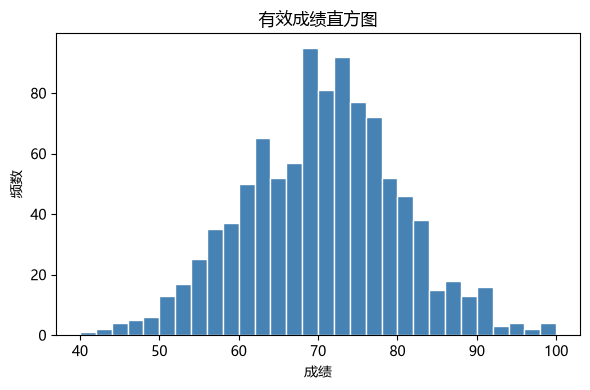

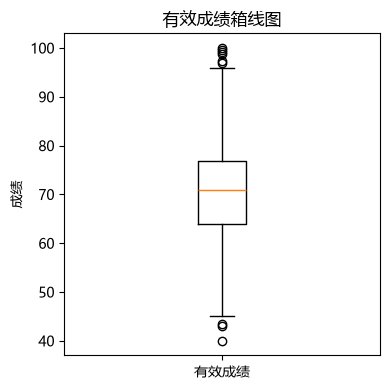

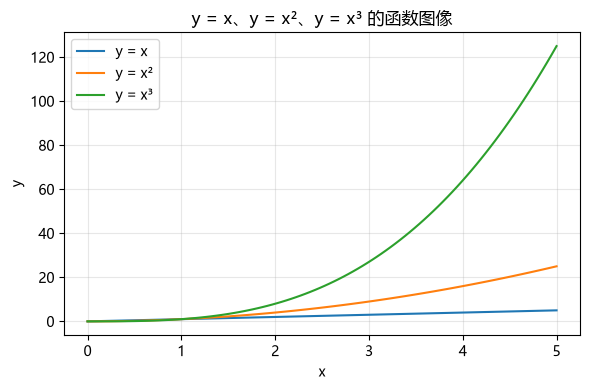

In [93]:
# 用有效成绩（去掉 nan）画直方图与箱线图；0<=x<=5 画 y=x, y=x^2, y=x^3
valid_scores = scores_with_nan[~np.isnan(scores_with_nan)]   

# 删除无意义的东西
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False  

# 图1：直方图
plt.figure(figsize=(6, 4))
plt.hist(valid_scores, bins=30, color="steelblue", edgecolor="white")
plt.title("有效成绩直方图")
plt.xlabel("成绩")
plt.ylabel("频数")
plt.tight_layout()
plt.show()

# 图2：箱线图
plt.figure(figsize=(4, 4))
plt.boxplot(valid_scores, tick_labels=["有效成绩"])
plt.title("有效成绩箱线图")
plt.ylabel("成绩")
plt.tight_layout()
plt.show()

# 图3：三条函数折线（同一坐标系）
x = np.linspace(0, 5, 100)
plt.figure(figsize=(6, 4))
plt.plot(x, x, label="y = x")
plt.plot(x, x**2, label="y = x²")
plt.plot(x, x**3, label="y = x³")
plt.title("y = x、y = x²、y = x³ 的函数图像")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 实验4：pandas Series、DataFrame 与内存中的CSV 读写
操作任务：
1. 使用以下模拟数据创建 DataFrame，行索引为姓名；计算 Total（三科总分）和
Average（三科平均分）两列。输出行索引、列名、前 3 行和基本统计信息。

records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

2. 分别用 loc 和 iloc 读取 Carol 的记录，并筛选平均分不低于 80 的学生。
3. 分别用 mean(axis=0) 和 mean(axis=1) 计算三科成绩的列均值和每名学生的
行均值。
4. 使用 apply() 计算每名学生的三科最高分，使用 agg() 一次得到每科的最小值、
均值和最大值。任选一列使用 rank() 给学生排名。
5. 按 Group 分组，统计每组人数和三科平均分。再用 transform('mean') 为每行
增加其所在组的 Python 平均分。
6. 用 filter() 保留 Python 平均分不低于 80 的组；输出保留的组和学生。
7. 计算三科成绩之间的协方差矩阵和皮尔森相关系数矩阵；选择其中一对科目，解释
协方差符号与相关系数大小的含义。

In [94]:

import pandas as pd
import numpy as np

# 创建 DataFrame，行索引为姓名；计算 Total（三科总分） 和 Average（三科均分）
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")   # 行索引设为姓名

df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print(f"行索引: {df.index.tolist()}")
print(f"列名  : {df.columns.tolist()}")
print("前 3 行:")
print(df.head(3))
print("基本统计信息:")
print(df[["Math", "English", "Python", "Total", "Average"]].describe())

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名  : ['Group', 'Math', 'English', 'Python', 'Total', 'Average']
前 3 行:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
基本统计信息:
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [95]:
# loc 按行索引标签、iloc 按整数位置读取 Carol；筛选平均分不低于 80
print("loc 读取 Carol:")
print(df.loc["Carol"])

print("iloc 读取 Carol（第 3 行，位置 2）:")
print(df.iloc[2])

print("平均分不低于 80 的学生:")
print(df[df["Average"] >= 80])

loc 读取 Carol:
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
iloc 读取 Carol（第 3 行，位置 2）:
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
平均分不低于 80 的学生:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [96]:
# axis=0 列均值（每科），axis=1 行均值（每人三科）
print("三科列均值 mean(axis=0):")
print(df[["Math", "English", "Python"]].mean(axis=0))

print("每名学生行均值 mean(axis=1):")
print(df[["Math", "English", "Python"]].mean(axis=1))

三科列均值 mean(axis=0):
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64
每名学生行均值 mean(axis=1):
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [97]:
# apply 求每人三科最高分；agg 一次得到每科 min/mean/max；rank 排名
print("每人三科最高分 apply():")
print(df[["Math", "English", "Python"]].apply(max, axis=1))

print("每科最小值/均值/最大值 agg():")
print(df[["Math", "English", "Python"]].agg(["min", "mean", "max"]))

print("按 Average 排名 rank():")
print(df["Average"].rank(ascending=False, method="min").astype(int))

每人三科最高分 apply():
Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
dtype: int64
每科最小值/均值/最大值 agg():
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000
按 Average 排名 rank():
Name
Alice    1
Bob      5
Carol    2
David    6
Eva      3
Frank    4
Name: Average, dtype: int64


In [98]:
# 按 Group 分组统计人数与三科平均分；transform('mean') 增加所在组的 Python 均分
grouped = df.groupby("Group")
print("每组人数:")
print(grouped.size())
print("每组三科平均分:")
print(grouped[["Math", "English", "Python"]].mean())

df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("增加组 Python 均分后的表:")
print(df[["Group", "Python", "Group_Python_Mean"]])

每组人数:
Group
A    3
B    3
dtype: int64
每组三科平均分:
            Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333
增加组 Python 均分后的表:
      Group  Python  Group_Python_Mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


In [99]:
# filter 保留 Python 平均分不低于 80 的组
kept = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
kept_groups = kept["Group"].unique()

print(f"保留的组: {list(kept_groups)}")
print("保留组中的学生:")
print(kept.index.tolist())

保留的组: ['A', 'B']
保留组中的学生:
['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']


In [100]:
# 三科成绩的协方差矩阵与皮尔森相关系数矩阵
subjects = ["Math", "English", "Python"]
print("协方差矩阵 cov():")
print(df[subjects].cov())

print("皮尔森相关系数矩阵 corr():")
print(df[subjects].corr())

# 以 Math 与 Python 为例解释
r = df["Math"].corr(df["Python"])
cov_mp = df["Math"].cov(df["Python"])
print(f"Math 与 Python: 协方差 = {cov_mp:.2f}，相关系数 = {r:.3f}")
print("解释: 协方差为正，说明 Math 与 Python 同向变化（数学越高 Python 越高）；")
print("相关系数接近 1，说明两科成绩呈较强的正线性相关关系。")

协方差矩阵 cov():
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667
皮尔森相关系数矩阵 corr():
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000
Math 与 Python: 协方差 = 74.93，相关系数 = 0.885
解释: 协方差为正，说明 Math 与 Python 同向变化（数学越高 Python 越高）；
相关系数接近 1，说明两科成绩呈较强的正线性相关关系。
